# Продукт

### Описание датасета
RetailRocket E-commerce Dataset( https://www.kaggle.com/datasets/retailrocket/ecommerce-dataset ) состоит из трех файлов: файла с данными о поведении (events.csv), файла со свойствами товаров (item_properties.csv) и файла, описывающего дерево категорий (category_tree.csv). Данные были собраны с реального веб-сайта электронной коммерции. Это необработанные данные, то есть без каких-либо преобразований содержимого, однако все значения хешированы в связи с конфиденциальностью. Цель публикации — стимулировать исследования в области рекомендательных систем с неявной обратной связью.

Данные о поведении пользователей, то есть события, такие как клики, добавление в корзину, транзакции, представляют собой взаимодействия, собранные за период в 4,5 месяца. Посетитель может совершать три типа событий: «просмотр», «добавление в корзину» или «транзакция». В общей сложности зафиксировано 2 756 101 событие, включая 2 664 312 просмотров, 69 332 добавления в корзину и 22 457 транзакций, совершенных 1 407 580 уникальными посетителями. Примерно для 90% событий соответствующие свойства можно найти в файле «item_properties.csv».

Файл со свойствами товаров (item_properties.csv) содержит 20 275 902 строки, то есть различные свойства, описывающие 417 053 уникальных товара. Файл разделен на 2 файла из-за ограничений по размеру. Поскольку свойство товара может меняться со временем (например, цена меняется со временем), каждая строка в файле имеет соответствующую временную метку. Другими словами, файл состоит из объединенных снимков для каждой недели в файле с данными о поведении. Однако, если свойство товара остается постоянным в течение наблюдаемого периода, в файле будет присутствовать только одно значение из снимка.

Файл с деревом категорий содержит 1669 строк. Каждая строка в файле указывает идентификатор дочерней категории (categoryId) и соответствующую родительскую категорию.


### Проблема
Для e-commerce типична низкая конверсия из просмотра в покупку: большинство посетителей уходят после первого визита, не совершив целевого действия. Платформа теряет потенциальную выручку на этапе мотивации к добавлению товара в корзину и на этапе чекаута. Без когортного анализа и оценки LTV невозможно понять, какие каналы и сегменты приносят ценность, а какие — только трафик.

### Целевая аудитория
Покупатели (visitors); менеджеры продукта и маркетинга,
отвечающие за конверсию, удержание и распределение бюджета на привлечение.

### Бизнес-модель
Транзакционная. Стоимость товара восстанавливается из item_properties (свойство '790', значения в тысячных долях), что позволяет оценить GMV и LTV в условных денежных единицах.


### Ограничения

- В датасете нет расходов на привлечение по каналам. 
- Период 4,5 месяца недостаточен для анализа годовой сезонности
- Цена восстанавливается из недельных снимков item_properties; для транзакций используется последняя известная цена на момент события

### Репозиторий

    pa/
    --README.md
    --requirements.txt
    --.gitignore
    --pas1.ipynb
    --data/
    ---category_tree.csv
    ---events.csv
    ---item_properties_part1.csv
    ---item_properties_part2.csv



Как запустить:

1. Скачать датасет с Kaggle: retailrocket/ecommerce-dataset
2. Положить 4 CSV в папку data/ рядом с ноутбуком
3. pip install -r requirements.txt
4. Открыть pas1.ipynb и выполнить все ячейки

**requirements.txt:** pandas, numpy, matplotlib, seaborn, jupyter

**.gitignore:** *.csv, __pycache__/, *.ipynb_checkpoints, .kaggle/, kaggle.json

**README.md:** описание задачи, источник данных, инструкция запуска, структура.


## Данные

Источник: RetailRocket E-commerce Dataset, Kaggle (`retailrocket/ecommerce-dataset`). Собран с реального e-commerce сайта, все значения хэшированы в целях конфиденциальности.

Объём - 2 756 101 событие, 1 407 580 уникальных посетителей, 22 457 транзакций, 417 053 товара. Период: 2015-05-03 — 2015-09-18 (137 дней).

Датасет распространяется через Kaggle для исследовательских
целей; при публикации результатов указывается источник (RetailRocket).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

plt.style.use('seaborn-v0_8')
sns.set_palette("husl")
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')

DATA_DIR = Path('data')

events = pd.read_csv(DATA_DIR / 'events.csv')
item_props = pd.concat([
    pd.read_csv(DATA_DIR / 'item_properties_part1.csv'),
    pd.read_csv(DATA_DIR / 'item_properties_part2.csv'),
], ignore_index=True)
category_tree = pd.read_csv(DATA_DIR / 'category_tree.csv')

print("events:", events.shape)
print("item_properties:", item_props.shape)
print("category_tree:", category_tree.shape)
events.head()

events: (2756101, 5)
item_properties: (20275902, 4)
category_tree: (1669, 2)


,timestamp,visitorid,event,itemid,transactionid
0,1433221332117,257597,view,355908,NaN
1,1433224214164,992329,view,248676,NaN
2,1433221999827,111016,view,318965,NaN
3,1433221955914,483717,view,253185,NaN
4,1433221337106,951259,view,367447,NaN


### Конвертация времени и границы периода.

Timestamp хранится в Unix-миллисекундах. Приводим к datetime и фиксируем  
минимальную/максимальную дату

In [2]:
events['datetime'] = pd.to_datetime(events['timestamp'], unit='ms')
item_props['datetime'] = pd.to_datetime(item_props['timestamp'], unit='ms')

print("Период событий:")
print("  Начало:", events['datetime'].min())
print("  Конец :", events['datetime'].max())
print("  Длительность (дней):",
      (events['datetime'].max() - events['datetime'].min()).days)

print("\nТипы событий:")
print(events['event'].value_counts())

Период событий:
  Начало: 2015-05-03 03:00:04.384000
  Конец : 2015-09-18 02:59:47.788000
  Длительность (дней): 137

Типы событий:
event
view           2664312
addtocart        69332
transaction      22457
Name: count, dtype: int64


### Проверка качества: пропуски, дубли, выбросы

In [3]:
print("=== ПРОПУСКИ ===")
print(events.isnull().sum())

print("\n=== ДУБЛИКАТЫ ===")
n_dup = events.duplicated().sum()
print("Полные дубликаты в events:", n_dup)

events = events.drop_duplicates().reset_index(drop=True)
print("После удаления дубликатов:", len(events))

print("\n=== ВЫБРОСЫ: события на пользователя ===")
events_per_user = events.groupby('visitorid').size()
print(events_per_user.describe())
print("\nТоп-5 'шустрых' пользователей:")
print(events_per_user.nlargest(5))

tx = events[events['event'] == 'transaction']
print("\nТранзакции без transactionid:", tx['transactionid'].isnull().sum())
dup_tx = tx.groupby('transactionid')['visitorid'].nunique()
print("transactionid, привязанные к >1 пользователю:", (dup_tx > 1).sum())

=== ПРОПУСКИ ===
timestamp              0
visitorid              0
event                  0
itemid                 0
transactionid    2733644
datetime               0
dtype: int64

=== ДУБЛИКАТЫ ===
Полные дубликаты в events: 460
После удаления дубликатов: 2755641

=== ВЫБРОСЫ: события на пользователя ===
count   1,407,580.0000
mean            1.9577
std            12.5798
min             1.0000
25%             1.0000
50%             1.0000
75%             2.0000
max         7,757.0000
dtype: float64

Топ-5 'шустрых' пользователей:
visitorid
1150086    7757
530559     4328
152963     3024
895999     2474
163561     2410
dtype: int64

Транзакции без transactionid: 0
transactionid, привязанные к >1 пользователю: 0


### Восстановление цены товара

Цена хранится в item_properties (свойство price) в тысячных долях.  
Извлекаем её, чтобы затем посчитать LTV/GMV.

In [4]:
prices = item_props.loc[item_props['property'] == '790',
                        ['itemid', 'datetime', 'value']].copy()
prices['value_clean'] = (prices['value'].astype(str)
                         .str.replace(r'^n', '', regex=True))
prices['price'] = pd.to_numeric(prices['value_clean'], errors='coerce') / 1000.0

n_bad = prices['price'].isna().sum()
print(f"Строк с нечисловой ценой: {n_bad} из {len(prices)}")

prices = prices.dropna(subset=['price']).sort_values(['itemid', 'datetime'])
print("Уникальных товаров с ценой:", prices['itemid'].nunique())
print(prices[['itemid', 'datetime', 'price']].head())

price_index = {}
for itemid, grp in prices.groupby('itemid'):
    price_index[itemid] = (grp['datetime'].values, grp['price'].values)

def price_at(itemid, ts):
    entry = price_index.get(itemid)
    if entry is None:
        return np.nan
    dates, vals = entry
    idx = np.searchsorted(dates, np.datetime64(ts), side='right') - 1
    if idx < 0:
        return vals[0]
    return vals[idx]

Строк с нечисловой ценой: 0 из 1790516
Уникальных товаров с ценой: 417053
          itemid            datetime   price
11431790       0 2015-05-10 03:00:00 91.2000
2003267        1 2015-05-10 03:00:00  5.7600
2798399        1 2015-05-17 03:00:00  5.7600
2400833        1 2015-05-24 03:00:00  5.7600
2202050        1 2015-05-31 03:00:00  5.7600


### Определения:
- *Активный пользователь* — посетитель, совершивший ≥1 событие в календарный день.
- *Конверсия* — доля пользователей, перешедших со шага A на шаг B воронки.
- *Retention* — доля пользователей когорты, вернувшихся на N-й неделе после первого визита.
- *Когорта* — группа пользователей, впервые появившихся на одной календарной неделе.
- *Правило оттока* — пользователь считается отточным, если с момента его последнего события прошло более 30 дней до даты среза. В расчёт включаются только пользователи с окном наблюдения ≥ 30 дней.

In [5]:
CHURN_DAYS   = 30
FUNNEL_STEPS = ['view', 'addtocart', 'transaction']
COHORT_FREQ  = 'W'
print("Порог оттока:", CHURN_DAYS, "дней")
print("Этапы воронки:", FUNNEL_STEPS)

Порог оттока: 30 дней
Этапы воронки: ['view', 'addtocart', 'transaction']


## Метрики 

**North Star Metric — GMV / Количество транзакций**
Отражает прямую монетизацию; единая цель для продукта, маркетинга и финансов. Рост/падение GMV определяет приоритет квартала — инвестировать в привлечение, в конверсию или в удержание.

**Диагностическая 1 — конверсия `view → addtocart`**
Показывает, насколько карточки товаров, навигация и рекомендации мотивируют пользователя к целевому действию. Если конверсия ниже бенчмарка — A/B-тест карточек, рекомендаций,
УТП на странице категории.

**Диагностическая 2 — конверсия `addtocart → transaction`**
Показывает качество чекаута и наличие барьеров (доставка, оплата, регистрация). Если конверсия падает — упрощать оформление, тестировать условия доставки и способы оплаты, убирать обязательную регистрацию.

**Риск-метрика — 30-дневный Churn Rate («спящие»)**
Ранний индикатор оттока. Рост доли «спящих» среди новых когорт означает, что пользователи не находят ценность после первого визита.При Churn Rate > 80% для новых когорт — пересматривать онбординг,
запускать реактивационные кампании, анализировать первый пользовательский опыт.

### Связь метрик
NSM растёт, когда растут обе диагностические метрики. Они, в свою очередь,
опираются на retention, средний чек и повторные покупки. Риск-метрика
показывает, не «сгорает» ли база новых пользователей раньше, чем они успевают
дойти до покупки.

## Трекинг событий

Каждое событие привязано к метрике и к конкретному полю датасета.

In [6]:
tracking = pd.DataFrame([
    {"Событие": "view",
     "Триггер": "Посетитель открыл карточку товара",
     "Параметры": "visitorid, itemid, timestamp",
     "Метрика": "Вовлечённость / верх воронки",
     "Этап пути": "Просмотр",
     "Поле датасета": "events.event == 'view'"},
    {"Событие": "addtocart",
     "Триггер": "Посетитель добавил товар в корзину",
     "Параметры": "visitorid, itemid, timestamp",
     "Метрика": "Конверсия view → addtocart",
     "Этап пути": "Микроконверсия",
     "Поле датасета": "events.event == 'addtocart'"},
    {"Событие": "transaction",
     "Триггер": "Посетитель завершил покупку",
     "Параметры": "visitorid, itemid, transactionid, timestamp",
     "Метрика": "NSM (Транзакции / GMV)",
     "Этап пути": "Покупка",
     "Поле датасета": "events.event == 'transaction'"},
    {"Событие": "price_snapshot",
     "Триггер": "Обновление цены товара (недельный снимок)",
     "Параметры": "itemid, property='790', value",
     "Метрика": "GMV / LTV",
     "Этап пути": "Атрибут товара",
     "Поле датасета": "item_properties.property == '790'"},
    {"Событие": "category_view",
     "Триггер": "Просмотр товара из категории X",
     "Параметры": "itemid → categoryid",
     "Метрика": "Сегментация воронки",
     "Этап пути": "Аналитический срез",
     "Поле датасета": "category_tree.categoryid"},
])
tracking

,Событие,Триггер,Параметры,Метрика,Этап пути,Поле датасета
0,view,Посетитель открыл карточку товара,"visitorid, itemid, timestamp",Вовлечённость / верх воронки,Просмотр,events.event == 'view'
1,addtocart,Посетитель добавил товар в корзину,"visitorid, itemid, timestamp",Конверсия view → addtocart,Микроконверсия,events.event == 'addtocart'
2,transaction,Посетитель завершил покупку,"visitorid, itemid, transactionid, timestamp",NSM (Транзакции / GMV),Покупка,events.event == 'transaction'
3,price_snapshot,Обновление цены товара (недельный снимок),"itemid, property='790', value",GMV / LTV,Атрибут товара,item_properties.property == '790'
4,category_view,Просмотр товара из категории X,itemid → categoryid,Сегментация воронки,Аналитический срез,category_tree.categoryid


## Первые расчёты

Для трека Б обязательны **когортный retention** и **LTV/CAC**. Дополнительно —
воронка и сегментный срез по категориям (требование «таблица или график
с выводом»).

### Воронка конверсии

       Этап  Уникальные пользователи  Конверсия от View (%)  Шаговая конверсия (%)
       View                  1404179               100.0000               100.0000
  AddToCart                    37722                 2.6864                 2.6864
Transaction                    11719                 0.8346                31.0668


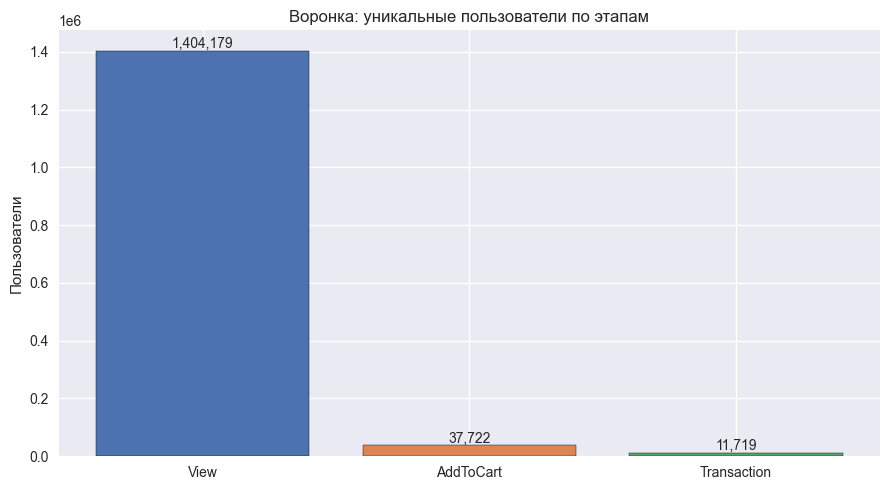

In [7]:
users_view = events.loc[events['event'] == 'view', 'visitorid'].nunique()
users_cart = events.loc[events['event'] == 'addtocart', 'visitorid'].nunique()
users_tx   = events.loc[events['event'] == 'transaction', 'visitorid'].nunique()

funnel = pd.DataFrame({
    'Этап': ['View', 'AddToCart', 'Transaction'],
    'Уникальные пользователи': [users_view, users_cart, users_tx],
    'Конверсия от View (%)': [
        100.0,
        users_cart / users_view * 100,
        users_tx   / users_view * 100,
    ],
    'Шаговая конверсия (%)': [
        100.0,
        users_cart / users_view * 100,
        users_tx   / max(users_cart, 1) * 100,
    ],
})
print(funnel.to_string(index=False))

plt.figure(figsize=(9, 5))
bars = plt.bar(funnel['Этап'], funnel['Уникальные пользователи'],
               color=['#4C72B0', '#DD8452', '#55A868'], edgecolor='black')
for b, v in zip(bars, funnel['Уникальные пользователи']):
    plt.text(b.get_x() + b.get_width()/2, v, f'{v:,}',
             ha='center', va='bottom', fontsize=10)
plt.title('Воронка: уникальные пользователи по этапам')
plt.ylabel('Пользователи')
plt.tight_layout()
plt.show()

### Вывод 

Наибольшая утечка на шаге `view → addtocart` (типично для e-commerce). 

Шаговая конверсия `addtocart → transaction` заметно выше — чекаут работает

Продуктовое решение: улучшать мотивацию к добавлению в корзину. Карточки товаров, рекомендации, УТП на странице категории.

### Когортный Retention

Недельные когорты по первому визиту; доля вернувшихся на N-й неделе.
Определения зафиксированы в разделе 3.

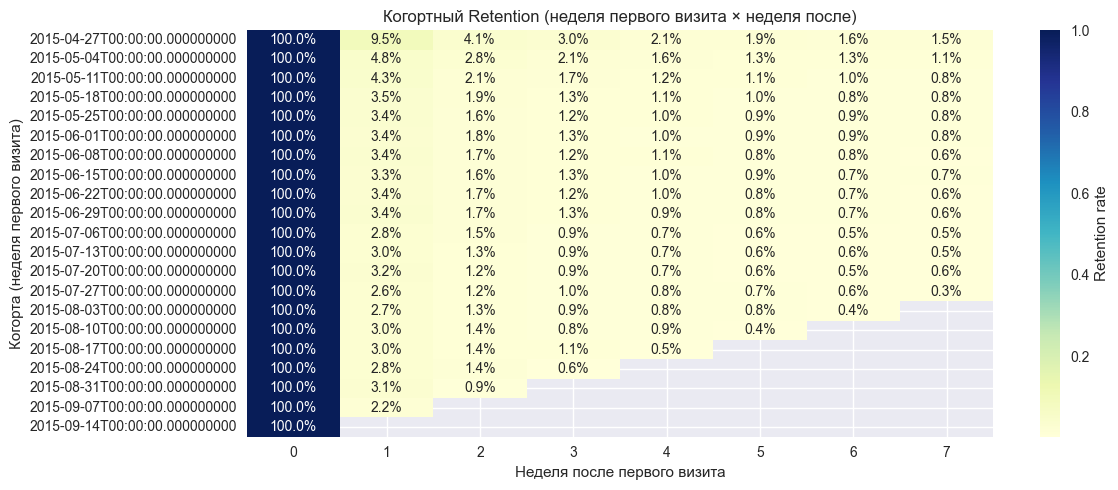


Средний Retention по неделям (все когорты):
week_number
0   1.0000
1   0.0353
2   0.0171
3   0.0126
4   0.0101
5   0.0088
6   0.0079
7   0.0072
dtype: float64


In [8]:
first_visit = (events.groupby('visitorid')['datetime']
                     .min()
                     .reset_index()
                     .rename(columns={'datetime': 'first_dt'}))
first_visit['cohort_week'] = (first_visit['first_dt']
                              .dt.to_period(COHORT_FREQ).dt.start_time)

ev = events.merge(first_visit[['visitorid', 'cohort_week']],
                  on='visitorid', how='left')
ev['event_week'] = ev['datetime'].dt.to_period(COHORT_FREQ).dt.start_time
ev['week_number'] = ((ev['event_week'] - ev['cohort_week']).dt.days // 7)

cohort_size = (first_visit.groupby('cohort_week')['visitorid']
                          .nunique()
                          .rename('cohort_size'))

retention = (ev[ev['week_number'] >= 0]
             .groupby(['cohort_week', 'week_number'])['visitorid']
             .nunique()
             .reset_index()
             .merge(cohort_size, on='cohort_week'))
retention['retention_rate'] = retention['visitorid'] / retention['cohort_size']

pivot = retention.pivot(index='cohort_week',
                        columns='week_number',
                        values='retention_rate').iloc[:, :8]

plt.figure(figsize=(12, 5))
sns.heatmap(pivot, annot=True, fmt='.1%', cmap='YlGnBu',
            cbar_kws={'label': 'Retention rate'})
plt.title('Когортный Retention (неделя первого визита × неделя после)')
plt.xlabel('Неделя после первого визита')
plt.ylabel('Когорта (неделя первого визита)')
plt.tight_layout()
plt.show()

print("\nСредний Retention по неделям (все когорты):")
print(pivot.mean().round(4))

Вывод по retention

Кривая retention падает с W0 к W1 с 100% до 3.5% — норма для e-commerce: большинство посетителей уходят после первого визита. После W1 падение продолжается, но замедляется: W2=1.7%, W4=1.0%, W7=0.7%. Это означает, что «ядра» лояльных пользователей почти нет — каждый следующий возврат даётся всё труднее. Продуктовое решение: работать не только с реактивацией, но и с первым пользовательским опытом (онбординг, рекомендации на первом визите), чтобы поднять саму вероятность возврата на W1.

### 30-дневный Churn Rate

Доля пользователей, у которых с момента последнего события прошло больше CHURN_DAYS = 30 дней до даты среза. Чтобы метрика была корректной, считаем её только для пользователей, у которых было достаточно времени наблюдения (≥ 30 дней с первого визита до конца периода).

Дата среза: 2015-09-18 02:59:47.788000
Пользователей с достаточным окном наблюдения: 1,133,422 из 1,407,580

=== 30-дневный CHURN RATE ===
Отточных: 1,098,150 из 1,133,422
Churn Rate: 96.89%

Churn Rate по когортам:
             cohort_size  churn_rate_pct
cohort_week                             
2015-04-27          7865         98.0700
2015-05-04         71389         98.0300
2015-05-11         76662         98.2700
2015-05-18         78427         98.2600
2015-05-25         73231         98.3000
2015-06-01         72714         98.2800
2015-06-08         66586         98.3100
2015-06-15         69757         98.2500
2015-06-22         68400         98.1500
2015-06-29         68147         98.0800
2015-07-06         83944         98.1900
2015-07-13         80563         98.0300
2015-07-20         88261         97.8200
2015-07-27         73190         97.4200
2015-08-03         67081         96.7200
2015-08-10         64291         95.4000
2015-08-17         22914         49.6200


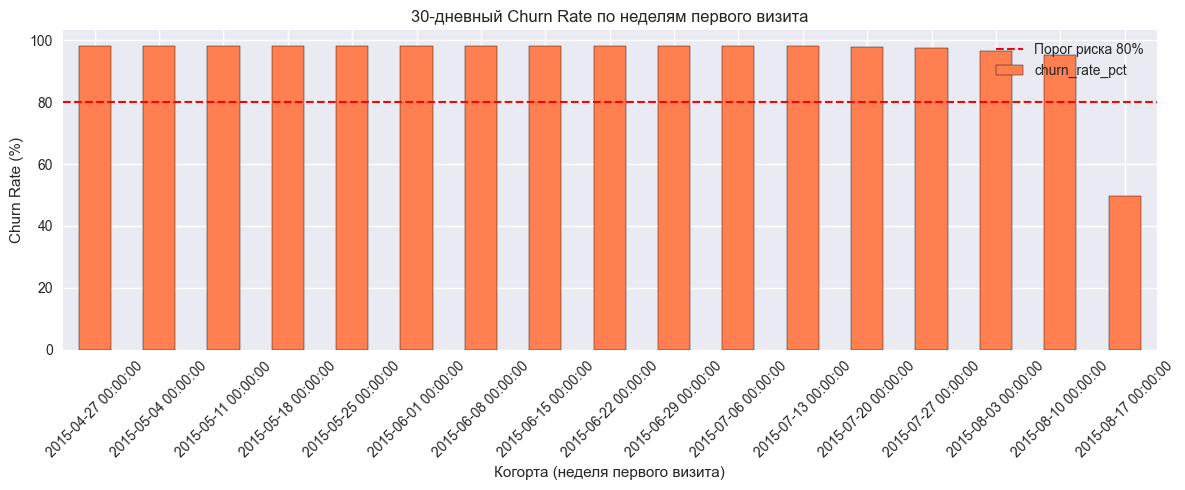

In [9]:
snapshot_date = events['datetime'].max()
print("Дата среза:", snapshot_date)

user_activity = (events.groupby('visitorid')['datetime']
                 .agg(first_seen='min', last_seen='max')
                 .reset_index())
user_activity['days_since_last'] = (snapshot_date - user_activity['last_seen']).dt.days
user_activity['observation_days'] = (snapshot_date - user_activity['first_seen']).dt.days

eligible = user_activity[user_activity['observation_days'] >= CHURN_DAYS].copy()
print(f"Пользователей с достаточным окном наблюдения: "
      f"{len(eligible):,} из {len(user_activity):,}")

eligible['is_churned'] = eligible['days_since_last'] > CHURN_DAYS

churn_rate = eligible['is_churned'].mean()
print(f"\n=== 30-дневный CHURN RATE ===")
print(f"Отточных: {eligible['is_churned'].sum():,} из {len(eligible):,}")
print(f"Churn Rate: {churn_rate:.2%}")

eligible['cohort_week'] = eligible['first_seen'].dt.to_period(COHORT_FREQ).dt.start_time
churn_by_cohort = (eligible.groupby('cohort_week')['is_churned']
                   .agg(churn_rate='mean', cohort_size='size'))
churn_by_cohort['churn_rate_pct'] = churn_by_cohort['churn_rate'] * 100

print("\nChurn Rate по когортам:")
print(churn_by_cohort[['cohort_size', 'churn_rate_pct']].round(2).to_string())

plt.figure(figsize=(12, 5))
churn_by_cohort['churn_rate_pct'].plot(kind='bar', color='coral', edgecolor='black')
plt.axhline(y=80, color='red', linestyle='--', linewidth=1.5, label='Порог риска 80%')
plt.title('30-дневный Churn Rate по неделям первого визита')
plt.xlabel('Когорта (неделя первого визита)')
plt.ylabel('Churn Rate (%)')
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Вывод по риск-метрике.**

- **Общий 30-дневный Churn Rate = 96.89%.** Из 1 133 422 пользователей
  с достаточным окном наблюдения (≥ 30 дней до даты среза) 1 098 150
  отнесены к «спящим». Это типично для e-commerce с большим объёмом
  «одноразового» трафика: большинство посетителей совершают 1–2 события
  и не возвращаются.
- **Порог риска 80% превышен существенно** — проблема системная, а не
  привязана к отдельной когорте. Продуктовое решение: реактивационные
  кампании на 14–30-й день молчания (пока пользователь ещё «тёплый»)
  и пересмотр первого пользовательского опыта (онбординг, рекомендации
  на первом визите).
- **По когортам churn стабилен ~98%** (от 97.4% до 98.3% для когорт
  мая–июля), что подтверждает системный характер проблемы.
- **Последняя когорта (2015-08-17, 49.62%) — артефакт наблюдения.**
  У пользователей этой когорты окно наблюдения ~32 дня к дате среза
  (2015-09-18), поэтому часть из них ещё не успела «набрать» 30 дней
  с последнего события и формально не может быть отнесена к спящим.
  Это **не улучшение удержания**, а эффект усечённого окна. При
  интерпретации тренда последнюю когорту следует исключить.
- **Исключено из расчёта 274 158 пользователей** (19.5% от всех) —
  те, кто впервые пришёл менее 30 дней до даты среза. Для них
  классификация «отточный / не отточный» была бы некорректно

### LTV / CAC

**LTV** — в денежных единицах, через восстановление цены транзакций из `item_properties`

**CAC** нет поэтому фиксируем допущение

In [10]:
tx = events.loc[events['event'] == 'transaction',
                ['visitorid', 'itemid', 'datetime']].copy()

tx['price'] = [price_at(i, t) for i, t in zip(tx['itemid'], tx['datetime'])]

print("Транзакций с ценой:", tx['price'].notna().sum(), "из", len(tx))
print("Средний чек:", round(tx['price'].mean(), 2))
print("Медианный чек:", round(tx['price'].median(), 2))

tx_priced = tx.dropna(subset=['price'])
user_rev  = tx_priced.groupby('visitorid')['price'].sum()
user_tx   = tx_priced.groupby('visitorid').size()

total_users   = events['visitorid'].nunique()
total_revenue = user_rev.sum()

ltv_all    = total_revenue / total_users
ltv_buyers = user_rev.mean()

print(f"\nВсего посетителей: {total_users:,}")
print(f"Всего покупателей: {len(user_rev):,}")
print(f"Общая выручка: {total_revenue:,.2f}")
print(f"LTV (на всех посетителей): {ltv_all:.2f}")
print(f"LTV (на покупателя):       {ltv_buyers:.2f}")
print(f"Среднее число транзакций на покупателя: {user_tx.mean():.2f}")

CAC_ASSUMED = 3.0
ltv_cac = ltv_all / CAC_ASSUMED
print(f"\n=== LTV/CAC ===")
print(f"CAC (допущение): {CAC_ASSUMED}")
print(f"LTV/CAC:         {ltv_cac:.2f}")

if ltv_cac >= 3:
    print(" Модель устойчива при данном допущении (LTV/CAC ≥ 3)")
else:
    print(" Требует оптимизации привлечения или повышения LTV")

Транзакций с ценой: 21982 из 22457
Средний чек: 107.93
Медианный чек: 47.16

Всего посетителей: 1,407,580
Всего покупателей: 11,569
Общая выручка: 2,372,495.24
LTV (на всех посетителей): 1.69
LTV (на покупателя):       205.07
Среднее число транзакций на покупателя: 1.90

=== LTV/CAC ===
CAC (допущение): 3.0
LTV/CAC:         0.56
 Требует оптимизации привлечения или повышения LTV


### Ограничение

В датасете RetailRocket нет расходов на маркетинг по каналам. Значение `CAC_ASSUMED = 3.0` — условное, введено для демонстрации методики LTV/CAC. В реальном проекте CAC берётся из отчётности маркетинга (затраты на канал ÷ число привлечённых клиентов)

### Сегментный срез: конверсия по категориям

In [11]:
cat = item_props[item_props['property'] == 'categoryid'][['itemid', 'value']]
cat = cat.drop_duplicates('itemid').rename(columns={'value': 'categoryid'})
cat['categoryid'] = pd.to_numeric(cat['categoryid'], errors='coerce')
cat = cat.dropna(subset=['categoryid'])
cat['categoryid'] = cat['categoryid'].astype(int)

ev_cat = events.merge(cat, on='itemid', how='left')

funnel_cat = (ev_cat.groupby(['event', 'categoryid'])
                    .size()
                    .unstack(level=0, fill_value=0)
                    .sort_values('view', ascending=False)
                    .head(10))
funnel_cat['conv_view_to_tx'] = funnel_cat['transaction'] / funnel_cat['view'] * 100
funnel_cat = funnel_cat.reset_index()[['categoryid', 'view', 'addtocart',
                                       'transaction', 'conv_view_to_tx']]
print("ТОП-10 категорий по просмотрам:")
print(funnel_cat.to_string(index=False))

ТОП-10 категорий по просмотрам:
 categoryid  view  addtocart  transaction  conv_view_to_tx
 1,051.0000 73014       1709          485           0.6643
 1,483.0000 61916       1382          437           0.7058
   959.0000 50112       1633          532           1.0616
   342.0000 45288       1278          281           0.6205
   683.0000 37657        905          211           0.5603
 1,279.0000 33531        720          123           0.3668
 1,613.0000 30618        830          135           0.4409
     5.0000 28952        576          186           0.6424
   646.0000 27669        484           87           0.3144
    48.0000 26701        600          146           0.5468


### Вывод

Категории с низкой конверсией `view → transaction` при высоком трафике это приоритет для продуктовой оптимизации. 

Категории с высокой конверсией — источник ядра лояльных покупателей; их стоит усиливать в маркетинге.

## Этика

Цель - Учебный анализ поведения пользователей для улучшения конверсии и
удержания.

Данные опубликованы для исследований; все идентификаторы (`visitorid`, `itemid`) захэшированы, персональные данные отсутствуют.

Персональные данные отсутствуют (нет возраста, пола, геолокации, платёжных данных).

Датасет распространяется через Kaggle для исследовательских целей; при публикации результатов указывается источник (RetailRocket).

Возможные риски: 

- Деанонимизация через комбинацию временных паттернов теоретически возможна;
  при агрегированном анализе (когорты, воронки) риск минимизирован.
- Не публиковать агрегаты по малым группам (< 10 пользователей)

В рамках проекта данные дополнительно никому не передаются: сырые CSV не публикуются в репозитории (исключены через `.gitignore`), не выкладываются на сторонние ресурсы и используются только локально для учебного анализа.

## Критерии успеха

| Метрика | Текущее (базовое) | Целевое | Способ проверки |
|---|---|---|---|
| Retention W4 | 1.0% | +5 п.п.-> 6.0%| Сравнение когорт до/после вмешательства |
| Конверсия addtocart→transaction | 31.1% | +3 п.п.-> 34.1% | A/B-тест в чекауте |
| Доля «спящих» (30-дневный churn) | 96.9% | −10 п.п.->86.9% | Когортный анализ после реактивационной кампании |

Поскольку данные исторические, критерии формулируются как цели для гипотетического продуктового вмешательства; способ проверки — сравнение с базовой линией на исторических когортах.При проверке churn-метрики
последняя когорта (2015-08-17) исключается из-за усечённого окна наблюдения

## Итоговые выводы

1. **Retention.** Кривая retention падает с 100% на W0 до 3.5% на W1, затем продолжает снижаться замедленными темпами: W2=1.7%, W4=1.0%, W7=0.7%. Устойчивого «плато» лояльных пользователей нет — удержание остаётся главной проблемой. Ключевая точка роста — первый пользовательский опыт (онбординг, рекомендации на первом визите)
2. **Риск-метрика подтверждает:** 30-дневный Churn Rate = 96.9% — большинство пользователей не возвращаются в течение месяца после первого визита. Порог риска 80% превышен существенно, проблема системная (churn стабилен ~98% по когортам мая–июля). Требуются реактивационные кампании на 14–30-й день молчания и пересмотр онбординга.
3. **Воронка.** Основное «протекание» — на шаге `view → addtocart`. Чекаут
   работает относительно хорошо; теряем на этапе мотивации.
4. **LTV/CAC.** При допущении CAC = 3.0, LTV/CAC = 0.56, что ниже нормы (≥ 3). Модель неустойчива, требуется оптимизация привлечения или повышение LTV через работу с повторными покупками
5. **Ограничения.** CAC — модельное допущение; период 4,5 месяца ограничивает
   анализ годовой сезонности. Оба пункта зафиксированы в разделе 2.